<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_01_from_tables_to_graphs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 1 · From tables to graphs

*M2 Network Analysis · Mapping collaboration with networks*

> **Today's question:** Most data comes as tables. How do we store *relationships* so that a computer can analyse them?

**You will learn to**

1. Explain why relational data is different from ordinary tabular data.
2. Store a network as an **edge list**, an **adjacency matrix** and a **node list**.
3. Build, inspect and draw a graph object in `networkx`.
4. Attach attributes to nodes and select sub-networks.

## The course storyline

Across six notebooks we follow one thread: **how inventors (and later countries and lawyers) collaborate**.
Each notebook answers one question and builds on the previous one.

| # | Notebook | The question |
|---|---|---|
| 1 | From tables to graphs | How do we store relationships? |
| 2 | From patents to a network | How do patent records become a collaboration network? |
| 3 | Who matters? | Which inventors are central, and in what sense? |
| 4 | Groups and the whole network | Is the network clustered, a small world, split into communities? |
| 5 | Zooming out: countries | How do countries collaborate, and who is the bridge? |
| 6 | Direction and layers | What changes when ties have a direction, and several types? |

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

## 1. Why networks?

A network (or *graph*) is a way of representing **relational data**: things (**nodes**) and the
relationships between them (**edges**, also called *ties* or *links*).

| Field | Nodes | Edges |
|---|---|---|
| Social networks | people, firms | friendship, advice, co-authorship, alliances |
| Innovation | inventors, patents, countries | co-inventing the same patent |
| Economics | firms, countries | trade, ownership, supply |
| Computer science | web pages, routers | hyperlinks, cables |
| Biology | proteins, species | interaction, who-eats-whom |

**Why not just use a table?** In a table, rows are (mostly) independent. In a network, observations
are *tied together*: remove one person and you also remove all their ties, which can change the
distance between people who never met them. Network measures are about these dependencies.

## 2. Three ways to store a network

### 2.1 Edge list
The most common format: one row per tie, with a **source** and a **target** column.
Extra columns (e.g. `weight`) describe the tie.

In [ ]:
edges = pd.DataFrame({
    "source": ["Jesper", "Jesper", "Jesper", "Pernille", "Pernille"],
    "target": ["Pernille", "Donald", "Dorte", "Jacob", "Dorte"],
})
edges

,source,target
0,Jesper,Pernille
1,Jesper,Donald
2,Jesper,Dorte
3,Pernille,Jacob
4,Pernille,Dorte


### 2.2 Adjacency matrix
An $n \times n$ table with a 1 where a tie exists and 0 otherwise.
For an **undirected** network the matrix is symmetric ($A_{ij} = A_{ji}$).

In [ ]:
G = nx.from_pandas_edgelist(edges, "source", "target")
A = nx.to_pandas_adjacency(G, dtype=int)
A

,Jesper,Pernille,Donald,Dorte,Jacob
Jesper,0,1,1,1,0
Pernille,1,0,0,1,1
Donald,1,0,0,0,0
Dorte,1,1,0,0,0
Jacob,0,1,0,0,0


Real networks are **sparse**: almost all cells are 0. That is why software usually stores the matrix in a
*sparse* format that only remembers the non-zero cells:

In [ ]:
A_sparse = nx.to_scipy_sparse_array(G)
print(f"{A.size} cells, but only {A_sparse.nnz} are non-zero")

25 cells, but only 10 are non-zero


### 2.3 Node list
Edge lists and matrices only store *who is connected to whom*. Information about the nodes themselves
(gender, group, country, ...) lives in a separate **node list**.

In [ ]:
nodes = pd.DataFrame({
    "name":  ["Jesper", "Pernille", "Jacob", "Dorte", "Donald"],
    "sex":   ["M", "F", "M", "F", "M"],
    "group": ["A", "B", "B", "A", "C"],
})
nodes

,name,sex,group
0,Jesper,M,A
1,Pernille,F,B
2,Jacob,M,B
3,Dorte,F,A
4,Donald,M,C


## 3. The graph object

A **graph object** keeps nodes, edges and their attributes together, and lets us run graph algorithms.
In `networkx` there are four classes:

| | undirected | directed |
|---|---|---|
| **single ties** | `nx.Graph` | `nx.DiGraph` |
| **multiple ties allowed** | `nx.MultiGraph` | `nx.MultiDiGraph` |

Any of these can be **weighted** (an edge attribute `weight`). Networks can also be **two-mode**
(two kinds of nodes, Part 2) or **multiplex** (several kinds of ties, Part 6).

In [ ]:
# Attach the node list to the graph: attributes are stored as {node: {attribute: value}}
nx.set_node_attributes(G, nodes.set_index("name").to_dict("index"))

print(G)                          # summary
print(G.nodes(data=True))         # nodes with their attributes
print(G.edges())                  # edges

Graph with 5 nodes and 5 edges
[('Jesper', {'sex': 'M', 'group': 'A'}), ('Pernille', {'sex': 'F', 'group': 'B'}), ('Donald', {'sex': 'M', 'group': 'C'}), ('Dorte', {'sex': 'F', 'group': 'A'}), ('Jacob', {'sex': 'M', 'group': 'B'})]
[('Jesper', 'Pernille'), ('Jesper', 'Donald'), ('Jesper', 'Dorte'), ('Pernille', 'Jacob'), ('Pernille', 'Dorte')]


In [ ]:
print("Jesper's attributes:", G.nodes["Jesper"])
print("Jesper's neighbours:", list(G.neighbors("Jesper")))
print("Jesper's degree    :", G.degree("Jesper"))

Jesper's attributes: {'sex': 'M', 'group': 'A'}
Jesper's neighbours: ['Pernille', 'Donald', 'Dorte']
Jesper's degree    : 3


In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

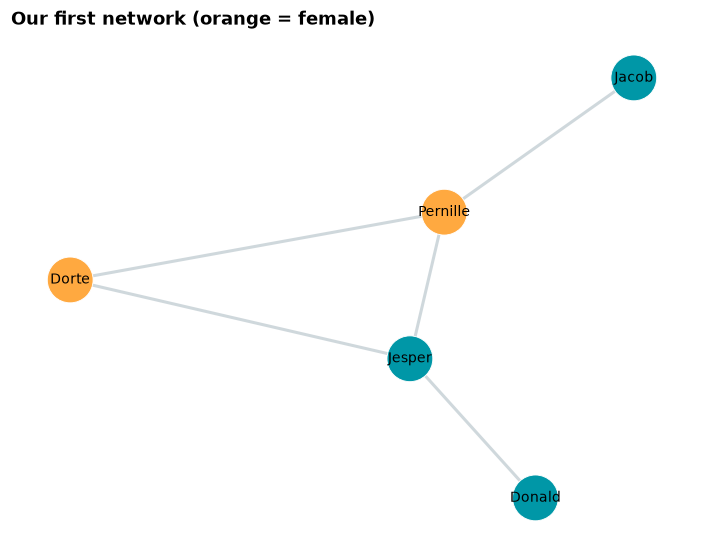

In [ ]:
pos_small = nx.spring_layout(G, seed=1)
colors = [ORANGE if G.nodes[n]["sex"] == "F" else TEAL for n in G]
draw(G, pos_small, node_size=900, node_color=colors, labels=True, font_size=9,
     title="Our first network (orange = female)", width=2)
plt.show()

### Selecting a sub-network
Select nodes with ordinary pandas logic, then keep only the ties among them with `G.subgraph()`.

In [ ]:
women = nodes.loc[nodes["sex"] == "F", "name"]
G_women = G.subgraph(women)
print(G_women, list(G_women.edges()))

Graph with 2 nodes and 1 edges [('Pernille', 'Dorte')]


## 4. Meet the 7-node graph from the lecture

In the slides we computed every measure **by hand** on this small graph. We will reuse it in Parts 3 and 4
to check that `networkx` gives exactly the numbers we computed with pen and paper.

In [ ]:
# The 7-node graph from the lecture slides (the one we worked through by hand)
toy = nx.Graph([("A", "B"), ("A", "C"), ("A", "D"), ("B", "C"), ("B", "D"),
                ("C", "D"), ("C", "E"), ("D", "E"), ("E", "F"), ("F", "G")])
toy_pos = {"A": (0, 1), "B": (0, -1), "C": (1.3, 1), "D": (1.3, -1),
           "E": (2.6, 0), "F": (3.9, 0), "G": (5.2, 0)}

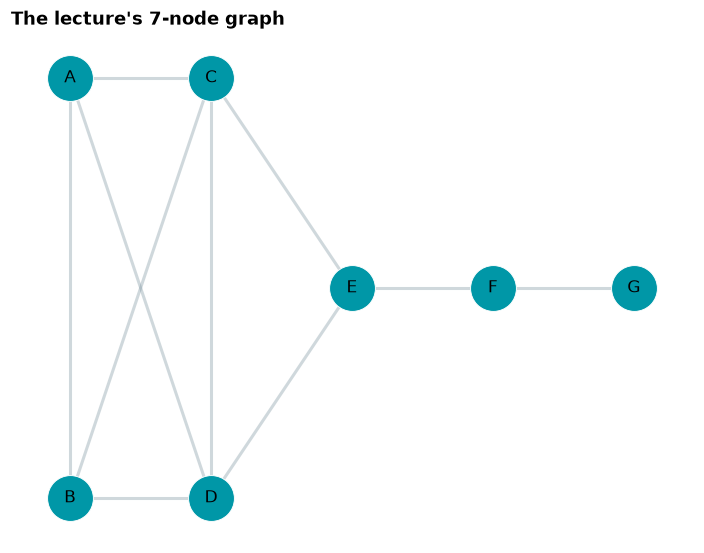

nodes: 7  edges: 10
degrees: {'A': 3, 'B': 3, 'C': 4, 'D': 4, 'E': 3, 'F': 2, 'G': 1}


In [ ]:
draw(toy, toy_pos, node_size=900, labels=True, font_size=11, width=2,
     title="The lecture's 7-node graph")
plt.show()

print("nodes:", toy.number_of_nodes(), " edges:", toy.number_of_edges())
print("degrees:", dict(toy.degree()))

## 🧑‍💻 Your turn

1. Build a graph with the edges `1-2, 1-3, 2-3, 3-4, 4-5, 4-6, 5-6` and draw it with labels.
2. What is the degree of node 4? Which nodes are its neighbours?
3. Store the graph as an adjacency matrix. Is it symmetric? Why?

<details><summary>Solution</summary>

```python
H = nx.Graph([(1, 2), (1, 3), (2, 3), (3, 4), (4, 5), (4, 6), (5, 6)])
draw(H, nx.spring_layout(H, seed=1), node_size=600, labels=True)
print(H.degree(4), list(H.neighbors(4)))
nx.to_pandas_adjacency(H, dtype=int)    # symmetric, because the graph is undirected
```
</details>

In [ ]:
# your code here

## ✅ Key takeaways
- A network = **nodes + edges** (+ attributes). It captures dependencies a table cannot.
- Store it as an **edge list** (most common), an **adjacency matrix** (sparse in practice) and a **node list**.
- `networkx` graph objects keep all three together: `G.nodes`, `G.edges`, `G.neighbors(n)`, `G.degree(n)`.

**Next → Part 2:** real data. We turn 6,000 rows of European patent records into a collaboration network.